In [ ]:
import pandas as pd

In [2]:
#load the dataset
dataset = pd.read_csv('Customer Churn.csv')

In [3]:
#Checking the first 5 rows of the dataset
pd.set_option('display.max_columns', None)
dataset.head(5)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [4]:
#Checking the distribution of the target variable
dataset["Churn"].value_counts()

Churn
0    2655
1     495
Name: count, dtype: int64

In [5]:
#Checking the shape of the dataset
dataset.shape

(3150, 14)

In [6]:
#Checking for duplicates in the dataset
dataset[dataset.duplicated()]

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
518,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
628,0,0,35,0,0,0,0,0,2,1,2,25,0.00,1
718,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
728,0,0,36,0,0,0,0,0,3,1,2,30,0.00,1
901,0,0,38,0,0,0,0,0,2,1,2,25,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.98,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.21,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.32,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.64,0


"300 duplicate rows (9.5%) found, removed because identical rows can leak between train and test; no ID column exists, so some may be genuine separate customers."

In [7]:
# how many, and what do they look like?
print(dataset.duplicated().sum())

300


In [8]:
 #do duplicates share the same churn label?
dups = dataset[dataset.duplicated(keep=False)]
print(dups["Churn"].value_counts())

Churn
0    384
1     81
Name: count, dtype: int64


In [9]:
dups = dataset[dataset.duplicated(keep=False)]
usage_cols = ["Seconds of Use", "Frequency of use", "Frequency of SMS", "Distinct Called Numbers"]

inactive = (dups[usage_cols].sum(axis=1) == 0)
print("All-zero usage rows:", inactive.sum())
print("Rows with real usage:", (~inactive).sum())

All-zero usage rows: 70
Rows with real usage: 395


300 duplicate rows (9.5%) found. 85% of the duplicated rows had non-zero usage values, so they are very likely genuine copies. They were removed to prevent train/test leakage. The 70 all-zero rows could be distinct inactive customers, but the dataset has no ID column, so this can't be confirmed. Removing them also does not change the churn ratio materially.

In [10]:
before = len(dataset)
dataset = dataset.drop_duplicates().reset_index(drop=True)
print(before, "->", len(dataset))          # expect 3150 -> 2850
print(dataset["Churn"].value_counts(normalize=True))

3150 -> 2850
Churn
0    0.843509
1    0.156491
Name: proportion, dtype: float64


In [11]:
print(dataset.shape)                # should be (2850, 14)
print(dataset.duplicated().sum())   # should be 0

(2850, 14)
0


In [12]:
#Checking the data types of each column
dataset.dtypes

Call  Failure                int64
Complains                    int64
Subscription  Length         int64
Charge  Amount               int64
Seconds of Use               int64
Frequency of use             int64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                  int64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64
dtype: object

In [13]:
#Checking the column names
dataset.columns

Index(['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value', 'Churn'],
      dtype='str')

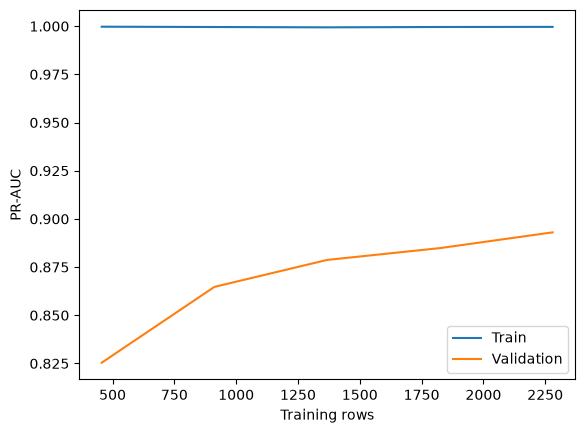

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

X = dataset.drop(columns=["Churn"])
y = dataset["Churn"]

sizes, train_scores, val_scores = learning_curve(
    RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
    X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="average_precision", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1)

plt.plot(sizes, train_scores.mean(axis=1), label="Train")
plt.plot(sizes, val_scores.mean(axis=1), label="Validation")
plt.xlabel("Training rows"); plt.ylabel("PR-AUC"); plt.legend(); plt.show()

### Learning Curve: Is the Dataset Large Enough?

I plotted PR-AUC against training size using stratified 5-fold cross-validation and a Random Forest. The validation score rises from about 0.83 at 500 training rows to about 0.89 at the full training size, and the curve is flattening but has not fully levelled off, so more data would help a little. Even so, a validation PR-AUC of about 0.89 shows the dataset is large enough for classical models.

The train score stays at 1.0 throughout, while validation is about 0.89. This gap means the Random Forest memorises the training data, which is expected on a small dataset with an unconstrained forest. I therefore rely on cross-validation and held-out test scores instead of training scores, and I keep hyperparameter tuning light (for example, limiting tree depth or setting a minimum samples per leaf).

In [17]:
dataset.columns = dataset.columns.str.strip().str.replace(r"\s+", " ", regex=True)  
print(dataset.isnull().sum())
print("Total missing:", dataset.isnull().sum().sum())
dataset.describe().T

Call Failure               0
Complains                  0
Subscription Length        0
Charge Amount              0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64
Total missing: 0


,count,mean,std,min,25%,50%,75%,max
Call Failure,2850.0,7.802456,7.326172,0.0,1.0000,6.00,12.00,36.00
Complains,2850.0,0.080702,0.272424,0.0,0.0000,0.00,0.00,1.00
Subscription Length,2850.0,32.452982,8.723075,3.0,29.0000,35.00,38.00,47.00
Charge Amount,2850.0,0.974737,1.550618,0.0,0.0000,0.00,2.00,10.00
Seconds of Use,2850.0,4534.243158,4199.712303,0.0,1458.7500,3041.00,6500.00,17090.00
Frequency of use,2850.0,70.484912,57.401512,0.0,28.0000,54.50,96.00,255.00
Frequency of SMS,2850.0,73.789825,112.062397,0.0,7.0000,22.00,88.00,522.00
Distinct Called Numbers,2850.0,23.870526,17.193929,0.0,11.0000,21.00,34.00,97.00
Age Group,2850.0,2.835088,0.893503,1.0,2.0000,3.00,3.00,5.00
Tariff Plan,2850.0,1.080351,0.271883,1.0,1.0000,1.00,1.00,2.00


### Missing Values and Value Ranges

All 14 columns have 2,850 non-null values, so there are no missing values and no imputation is needed. Value ranges are plausible: binary columns (`Complains`, `Churn`) are 0 to 1, `Tariff Plan` and `Status` are coded 1 to 2, `Age Group` is 1 to 5, and `Age` is 15 to 55. The zeros in the usage columns are genuine inactive customers, not placeholders. `Seconds of Use`, `Frequency of SMS` and `Customer Value` are strongly right-skewed.

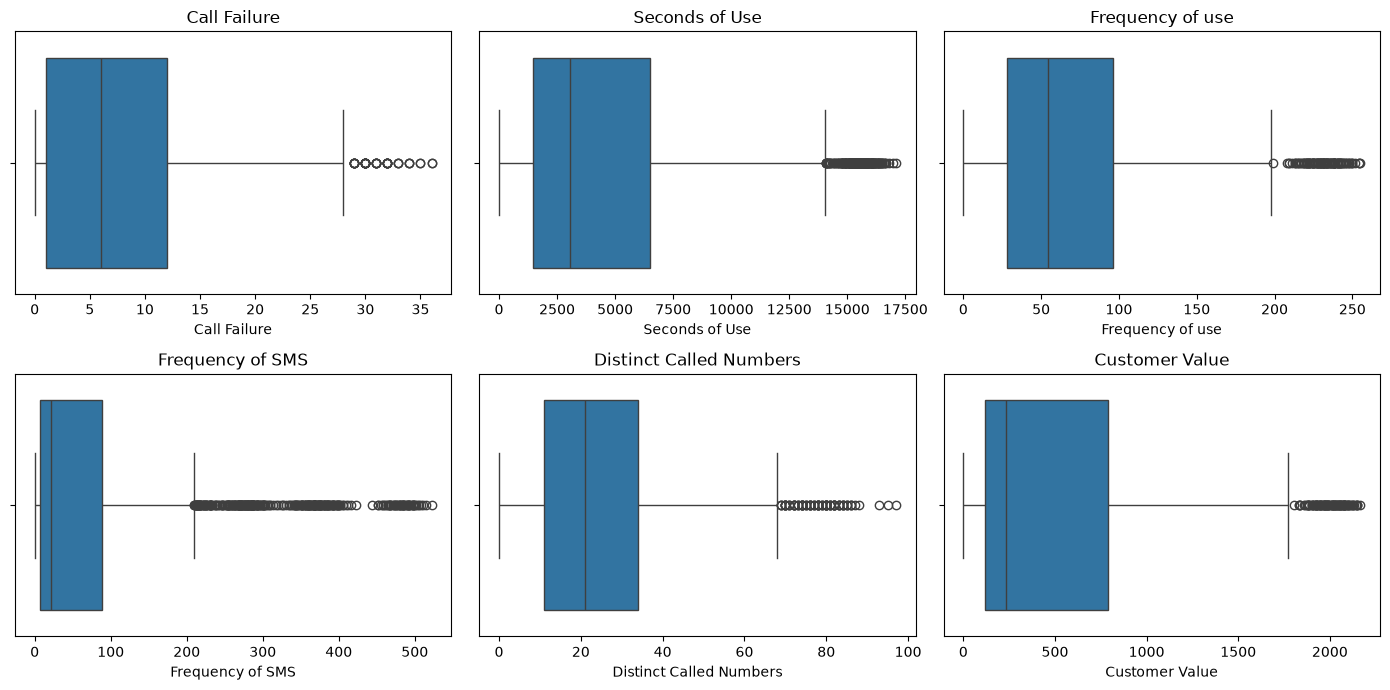

Call Failure: 44 outliers (1.5%)
Seconds of Use: 189 outliers (6.6%)
Frequency of use: 118 outliers (4.1%)
Frequency of SMS: 333 outliers (11.7%)
Distinct Called Numbers: 82 outliers (2.9%)
Customer Value: 104 outliers (3.6%)


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = ["Call Failure", "Seconds of Use", "Frequency of use",
        "Frequency of SMS", "Distinct Called Numbers", "Customer Value"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(x=dataset[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in cols:
    Q1, Q3 = dataset[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    n = ((dataset[col] < Q1 - 1.5 * IQR) | (dataset[col] > Q3 + 1.5 * IQR)).sum()
    print(f"{col}: {n} outliers ({n / len(dataset) * 100:.1f}%)")

### Outliers

I checked six usage and value columns with boxplots and the IQR rule. The share of outliers per column was: `Call Failure` 44 (1.5%), `Seconds of Use` 189 (6.6%), `Frequency of use` 118 (4.1%), `Frequency of SMS` 333 (11.7%), `Distinct Called Numbers` 82 (2.9%) and `Customer Value` 104 (3.6%).

These columns are right-skewed because a minority of customers use the service far more than the rest. Heavy users are genuine customers, not data errors, and there are no impossible values (see the ranges above). Removing them would delete real behaviour and shrink an already small dataset (2,850 rows), so I kept all rows unchanged.

Random Forest and XGBoost are not sensitive to outliers. For Logistic Regression, I scale the features with `StandardScaler`.

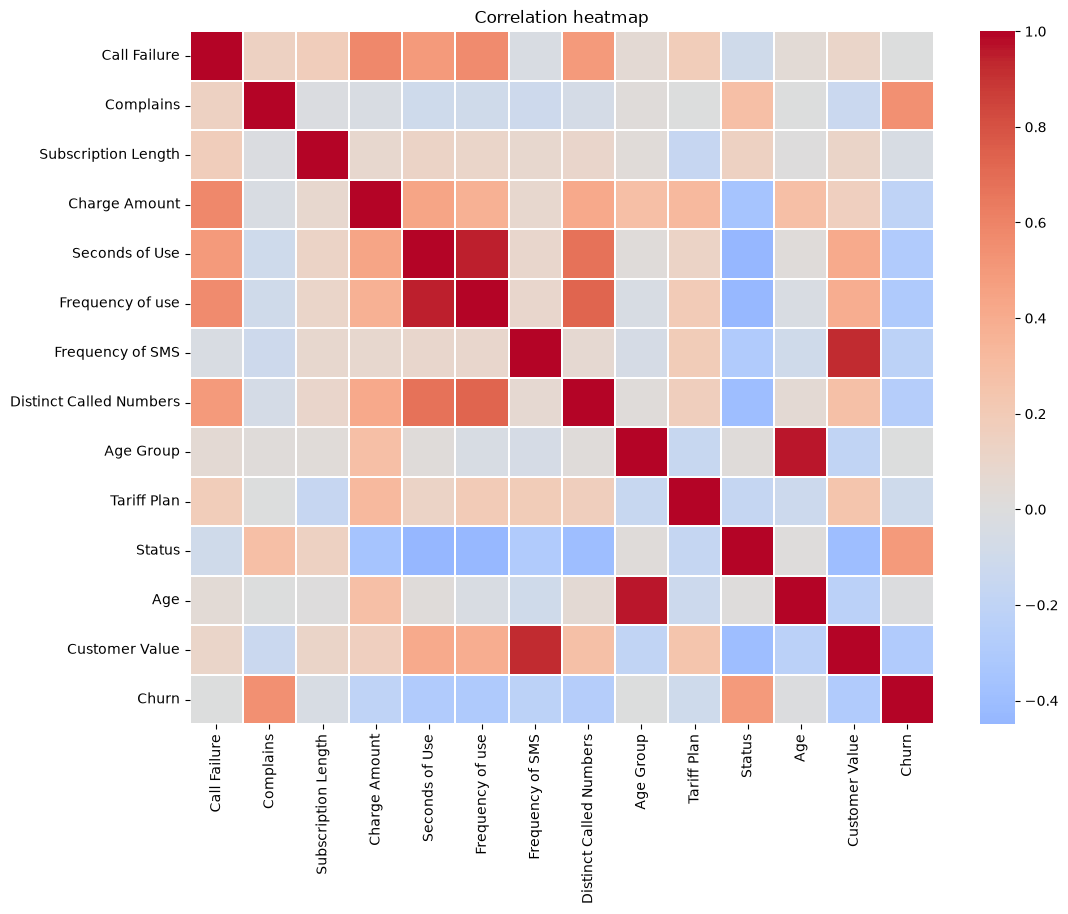

Complains                  0.546
Status                     0.493
Frequency of use          -0.299
Seconds of Use            -0.296
Customer Value            -0.287
Distinct Called Numbers   -0.270
Frequency of SMS          -0.219
Charge Amount             -0.202
Tariff Plan               -0.106
Subscription Length       -0.038
Age                       -0.011
Age Group                 -0.006
Call Failure               0.003
Name: Churn, dtype: float64
Age Group         Age                        0.960877
Seconds of Use    Frequency of use           0.945144
Frequency of SMS  Customer Value             0.922852
Frequency of use  Distinct Called Numbers    0.731204
Seconds of Use    Distinct Called Numbers    0.671973
Call Failure      Charge Amount              0.585442
                  Frequency of use           0.567096
dtype: float64


In [19]:
import numpy as np

corr = dataset.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Correlation heatmap")
plt.show()

print(corr["Churn"].drop("Churn").sort_values(key=abs, ascending=False).round(3))

feat = dataset.drop(columns=["Churn"]).corr().abs()
pairs = feat.where(~np.tril(np.ones(feat.shape)).astype(bool)).stack()
print(pairs[pairs > 0.5].sort_values(ascending=False))

In [20]:
print(pd.crosstab(dataset["Status"], dataset["Churn"], normalize="index").round(3))
print(pd.crosstab(dataset["Status"], dataset["Churn"]))

Churn       0      1
Status              
1       0.944  0.056
2       0.525  0.475
Churn      0    1
Status           
1       2045  121
2        359  325


### Correlation Analysis and Feature Decisions

The strongest correlations with `Churn` are `Complains` (0.546) and `Status` (0.493). The usage features (`Frequency of use`, `Seconds of Use`, `Customer Value`, `Distinct Called Numbers`, `Frequency of SMS`) are moderately negative (-0.22 to -0.30), meaning more active customers churn less. `Age`, `Age Group`, `Call Failure` and `Subscription Length` are close to zero.

Three feature pairs are highly correlated: `Age Group` and `Age` (0.96), `Seconds of Use` and `Frequency of use` (0.95), and `Frequency of SMS` and `Customer Value` (0.92).

**Leakage check on `Status`:** non-active customers (Status 2) churned 47.5% of the time (325 of 684), and active customers (Status 1) churned 5.6% (121 of 2,166). If `Status` merely recorded the outcome, non-active customers would churn almost 100% of the time, so it does not look like a direct leak. Because the dataset has no timestamps, I cannot confirm when `Status` was recorded, so I treat it as a strong predictor and note this as a limitation.

**Decisions:**
- Dropped `Age Group`, since it is a binned version of `Age` (0.96 correlation).
- Kept the other correlated usage features: tree-based models are not affected, and I scale features for Logistic Regression.
- Kept `Status` and `Complains`, the two strongest predictors. I will also train once without `Status` to show how much the model depends on it.


In [21]:
from sklearn.model_selection import train_test_split

dataset = dataset.drop(columns=["Age Group"])   # run once only

X = dataset.drop(columns=["Churn"])
y = dataset["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(4))
print(y_test.value_counts(normalize=True).round(4))

(2280, 12) (570, 12)
Churn
0    0.8434
1    0.1566
Name: proportion, dtype: float64
Churn
0    0.8439
1    0.1561
Name: proportion, dtype: float64


### Train/Test Split

I split the cleaned data 80/20 with a stratified split (`random_state=42`): 2,280 training rows and 570 test rows, each with 12 features (13 minus `Age Group`, which was dropped). Both sets keep the original churn rate (15.66% in training, 15.61% in test), so the test set reflects the real class balance. The test set is held out and used only once, for final evaluation. Any balancing (class weights or SMOTE) is applied to the training data only.

### Handling Class Imbalance and Model Comparison

Churn is about 84% / 16%. With only about 357 churners in the training set, undersampling would discard most of the data, so I compare two alternatives: class weights and SMOTE. Both are applied to the **training data only**; the test set keeps its natural ratio. SMOTE sits inside a pipeline so synthetic rows are created within each cross-validation fold and never leak into validation.

I compare Logistic Regression, Random Forest and XGBoost using stratified 5-fold cross-validation on the training set, then evaluate the finalists once on the untouched test set. Metrics: recall, precision, F1, ROC-AUC and PR-AUC. Accuracy is not reported, because always predicting "stayed" would score about 84% while catching no churners.

In [22]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos   # for XGBoost class weighting

def make_models():
    return {
        "LogReg + class weight": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
        "RandomForest + class weight": RandomForestClassifier(
            n_estimators=200, min_samples_leaf=3, class_weight="balanced",
            n_jobs=-1, random_state=42),
        "XGBoost + class weight": XGBClassifier(
            n_estimators=200, max_depth=3, learning_rate=0.1, scale_pos_weight=spw,
            eval_metric="logloss", n_jobs=-1, random_state=42),
        "LogReg + SMOTE": ImbPipeline([
            ("smote", SMOTE(random_state=42)),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000))]),
        "RandomForest + SMOTE": ImbPipeline([
            ("smote", SMOTE(random_state=42)),
            ("model", RandomForestClassifier(
                n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=42))]),
        "XGBoost + SMOTE": ImbPipeline([
            ("smote", SMOTE(random_state=42)),
            ("model", XGBClassifier(
                n_estimators=200, max_depth=3, learning_rate=0.1,
                eval_metric="logloss", n_jobs=-1, random_state=42))]),
    }

scoring = {"recall": "recall", "precision": "precision", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv = StratifiedKFold(5, shuffle=True, random_state=42)

rows = []
for name, model in make_models().items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name,
                 **{k: s[f"test_{k}"].mean() for k in scoring},
                 "PR-AUC std": s["test_pr_auc"].std()})

cv_results = pd.DataFrame(rows).set_index("Model").round(3)
cv_results.sort_values("pr_auc", ascending=False)

,recall,precision,f1,roc_auc,pr_auc,PR-AUC std
Model,,,,,,
XGBoost + class weight,0.922,0.761,0.833,0.979,0.916,0.026
RandomForest + class weight,0.924,0.773,0.842,0.981,0.906,0.040
XGBoost + SMOTE,0.891,0.719,0.795,0.975,0.904,0.032
RandomForest + SMOTE,0.902,0.768,0.829,0.980,0.895,0.054
LogReg + class weight,0.863,0.500,0.632,0.935,0.751,0.022
LogReg + SMOTE,0.882,0.459,0.603,0.928,0.739,0.022


### Model Comparison Results (5-fold stratified cross-validation, training set)

| Model | Recall | Precision | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| XGBoost + class weight | 0.922 | 0.761 | 0.833 | 0.979 | 0.916 |
| RandomForest + class weight | 0.924 | 0.773 | 0.842 | 0.981 | 0.906 |
| XGBoost + SMOTE | 0.891 | 0.719 | 0.795 | 0.975 | 0.904 |
| RandomForest + SMOTE | 0.902 | 0.768 | 0.829 | 0.980 | 0.895 |
| LogReg + class weight | 0.863 | 0.500 | 0.632 | 0.935 | 0.751 |
| LogReg + SMOTE | 0.882 | 0.459 | 0.603 | 0.928 | 0.739 |

**Observations:**
- Tree-based models clearly outperform Logistic Regression (PR-AUC about 0.90 to 0.92 vs 0.74 to 0.75), so the churn signal is non-linear.
- Class weights performed slightly better than SMOTE for both tree models and are simpler, since no synthetic rows are created.
- XGBoost and Random Forest with class weights are statistically close (differences under 0.01 are within fold-to-fold variation). XGBoost has the highest PR-AUC (0.916) and the lowest variance across folds (std 0.026).

**Decision:** I ship XGBoost with class weighting (`scale_pos_weight`). It has the best PR-AUC, the most stable cross-validation results, and provides probabilities for the app. Accuracy is not reported because the data is imbalanced.

                Recall  Precision     F1  ROC-AUC  PR-AUC
With Status      0.899      0.684  0.777    0.976   0.912
Without Status   0.899      0.690  0.780    0.971   0.897


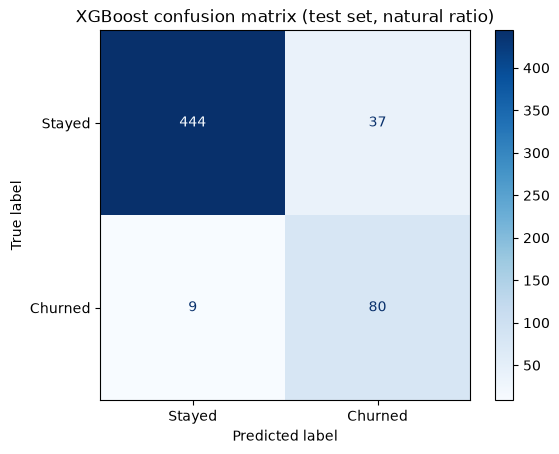

['churn_feature_columns.pkl']

In [23]:
from sklearn.metrics import (recall_score, precision_score, f1_score, roc_auc_score,
                             average_precision_score, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import joblib

def fit_eval(cols):
    m = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                      scale_pos_weight=spw, eval_metric="logloss",
                      n_jobs=-1, random_state=42)
    m.fit(X_train[cols], y_train)
    pred, proba = m.predict(X_test[cols]), m.predict_proba(X_test[cols])[:, 1]
    return m, {"Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred),
               "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, proba),
               "PR-AUC": average_precision_score(y_test, proba)}

all_cols = list(X_train.columns)
best_model, with_status = fit_eval(all_cols)
_, without_status = fit_eval([c for c in all_cols if c != "Status"])

print(pd.DataFrame([with_status, without_status],
                   index=["With Status", "Without Status"]).round(3))

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test[all_cols], y_test,
    display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("XGBoost confusion matrix (test set, natural ratio)")
plt.show()

joblib.dump(best_model, "xgb_churn_model.pkl")
joblib.dump(all_cols, "churn_feature_columns.pkl")

### Final Test-Set Evaluation and Dependence on `Status`

The XGBoost model with class weighting was evaluated once on the untouched test set (570 rows, about 89 churners): recall 0.899, precision 0.684, F1 0.777, ROC-AUC 0.976 and PR-AUC 0.912. These are close to the cross-validation results (PR-AUC 0.916, recall 0.922), so the model generalises well.

To check how much the model depends on `Status`, I retrained it without that feature. Recall was unchanged (0.899) and PR-AUC fell only from 0.912 to 0.897, so `Status` is useful but not essential, and the other features carry most of the signal. I kept `Status` in the final model because it scored best and the leakage check showed it does not simply record the outcome. The dataset has no timestamps, so I cannot confirm when `Status` was recorded, and I note this as a limitation. The test set is small, so differences of about 0.01 are within noise.

### Confusion Matrix: XGBoost (test set, natural ratio)

Out of 570 test customers:
- **True positives: 80** churners correctly flagged
- **False negatives: 9** churners the model missed (10.1% of the 89 churners)
- **False positives: 37** loyal customers flagged by mistake
- **True negatives: 444** loyal customers correctly cleared

The model catches about 90% of churners (recall 0.899), and about 68% of flagged customers actually churn (precision 0.684). For a retention team, a false positive costs a small offer or call to a customer who would have stayed, while a false negative is a lost customer, so I accept the extra false alarms. The test set holds only 89 churners, so one or two customers move recall by about a point.

In [1]:
import xgboost, sklearn
print(xgboost.__version__, sklearn.__version__)

3.4.1 1.9.0
